In [7]:
# import os
# os.environ["CUDA_VISIBLE_DEVICES"] = ""
# os.environ["FORCE_CPU"] = "1"
# import sys, types

# # Import only the YOLO class directly, bypassing ultralytics.__init__
# from ultralytics.models.yolo.model import YOLO

# # Build a fake "ultralytics" module that only contains YOLO
# ultralytics_stub = types.ModuleType("ultralytics")
# ultralytics_stub.YOLO = YOLO

# # Replace the real ultralytics with our stub
# sys.modules["ultralytics"] = ultralytics_stub
from torch.utils.data import DataLoader
from sinar.data.dynamic import CentroidMatrixDataset, GroupedBatchSampler

dataset = CentroidMatrixDataset.load("test-data.pt")

In [8]:
sampler = GroupedBatchSampler(dataset, batch_size=16)

loader = DataLoader(dataset, batch_sampler=sampler)



In [9]:
from matplotlib import pyplot as plt


def visualize_batches(loader, max_batches=2, grid_cols=5):
    for b_idx, (x, y) in enumerate(loader):
        # Add channel dim if missing
        if x.ndim == 3:
            x = x.unsqueeze(1)  # [batch, 1, 30, N]

        batch_size = x.shape[0]
        grid_rows = (batch_size + grid_cols - 1) // grid_cols

        fig, axes = plt.subplots(grid_rows, grid_cols, figsize=(3*grid_cols, 3*grid_rows))
        axes = axes.flatten()

        for i in range(batch_size):
            axes[i].imshow(x[i, 0].cpu().numpy(), cmap="viridis", aspect="auto")
            label = "Gang" if y[i].item() == 1 else "Normal"
            axes[i].set_title(label)
            axes[i].axis("off")

        # Hide empty subplots if batch not perfectly divisible
        for j in range(batch_size, len(axes)):
            axes[j].axis("off")

        plt.suptitle(f"Batch {b_idx} (size={batch_size}) shape=({x.shape[-2]},{x.shape[-1]})", fontsize=14)
        plt.tight_layout()
        plt.show()

        if b_idx + 1 >= max_batches:
            break

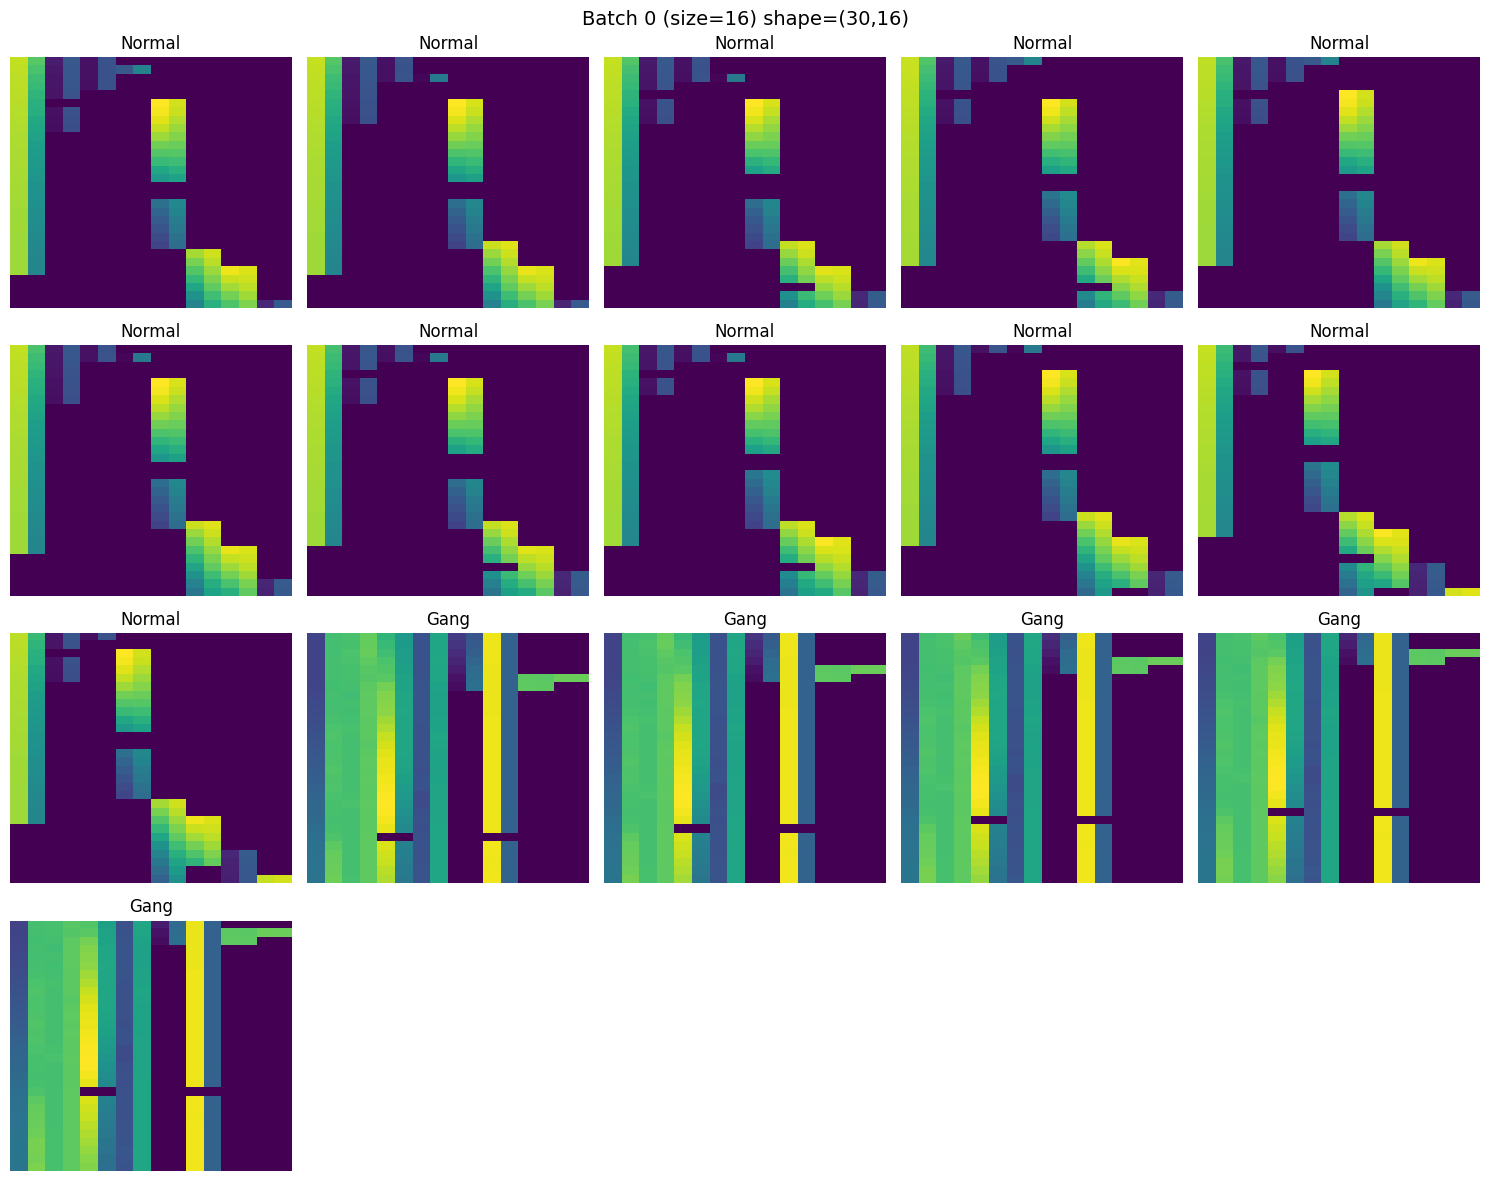

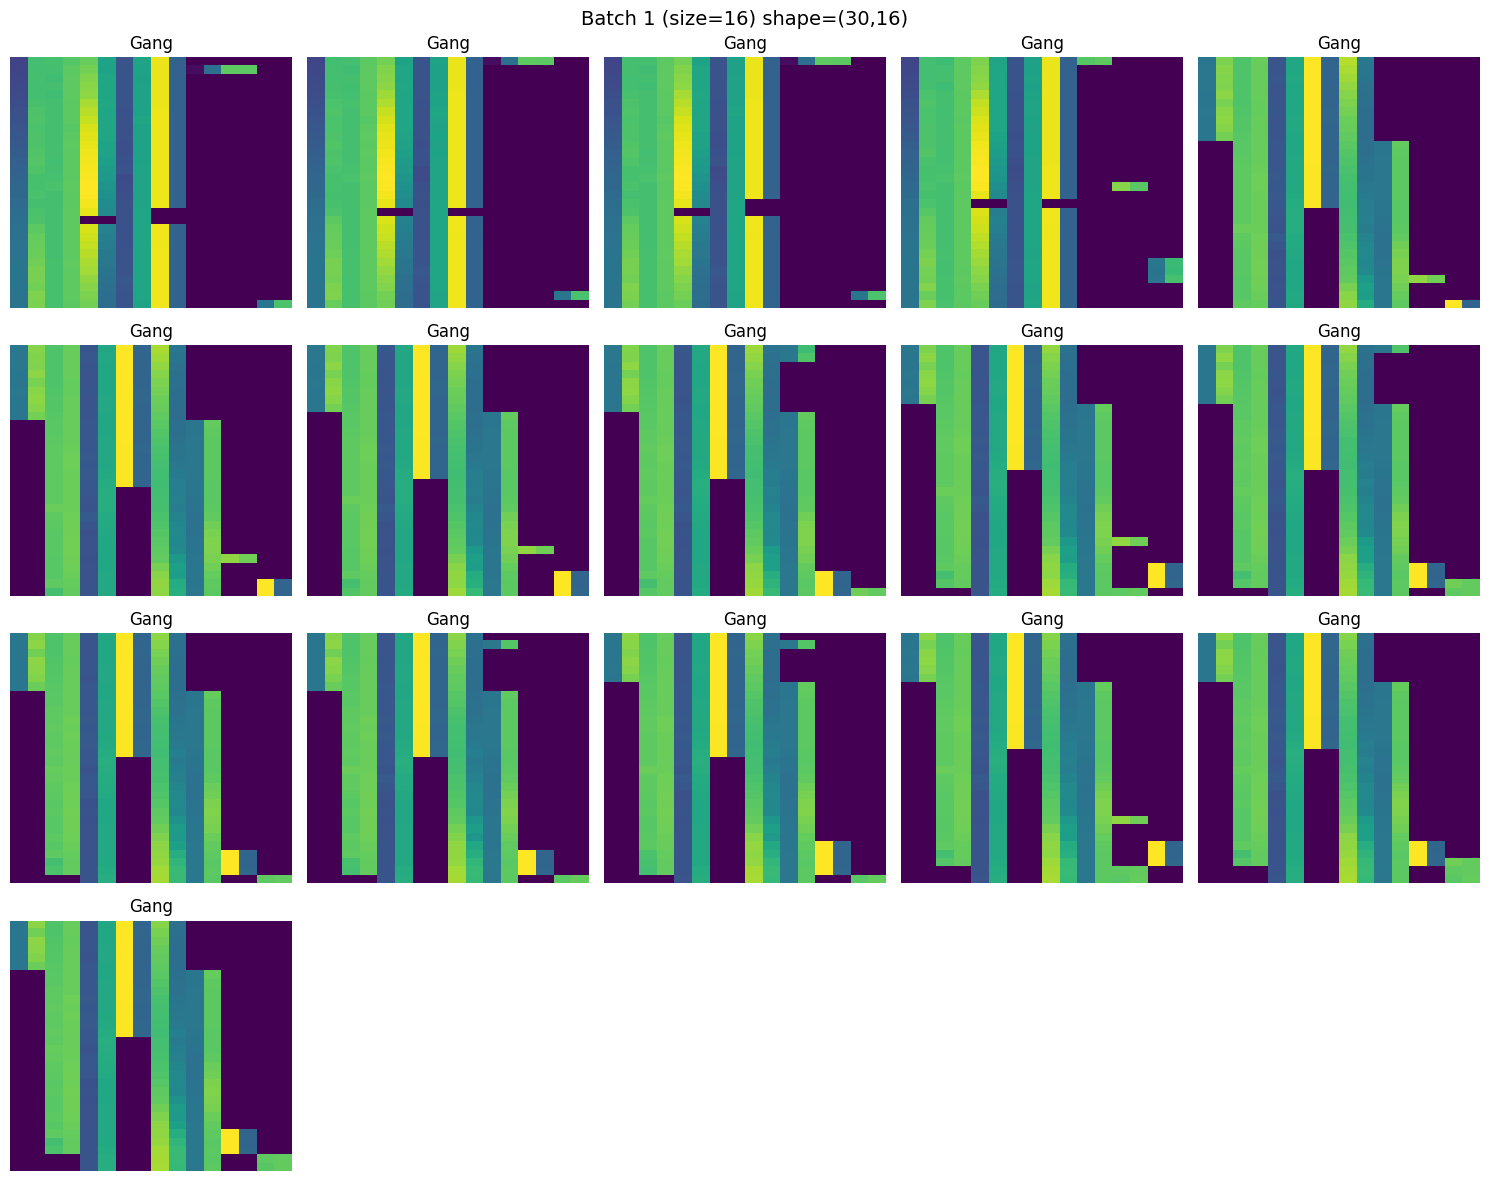

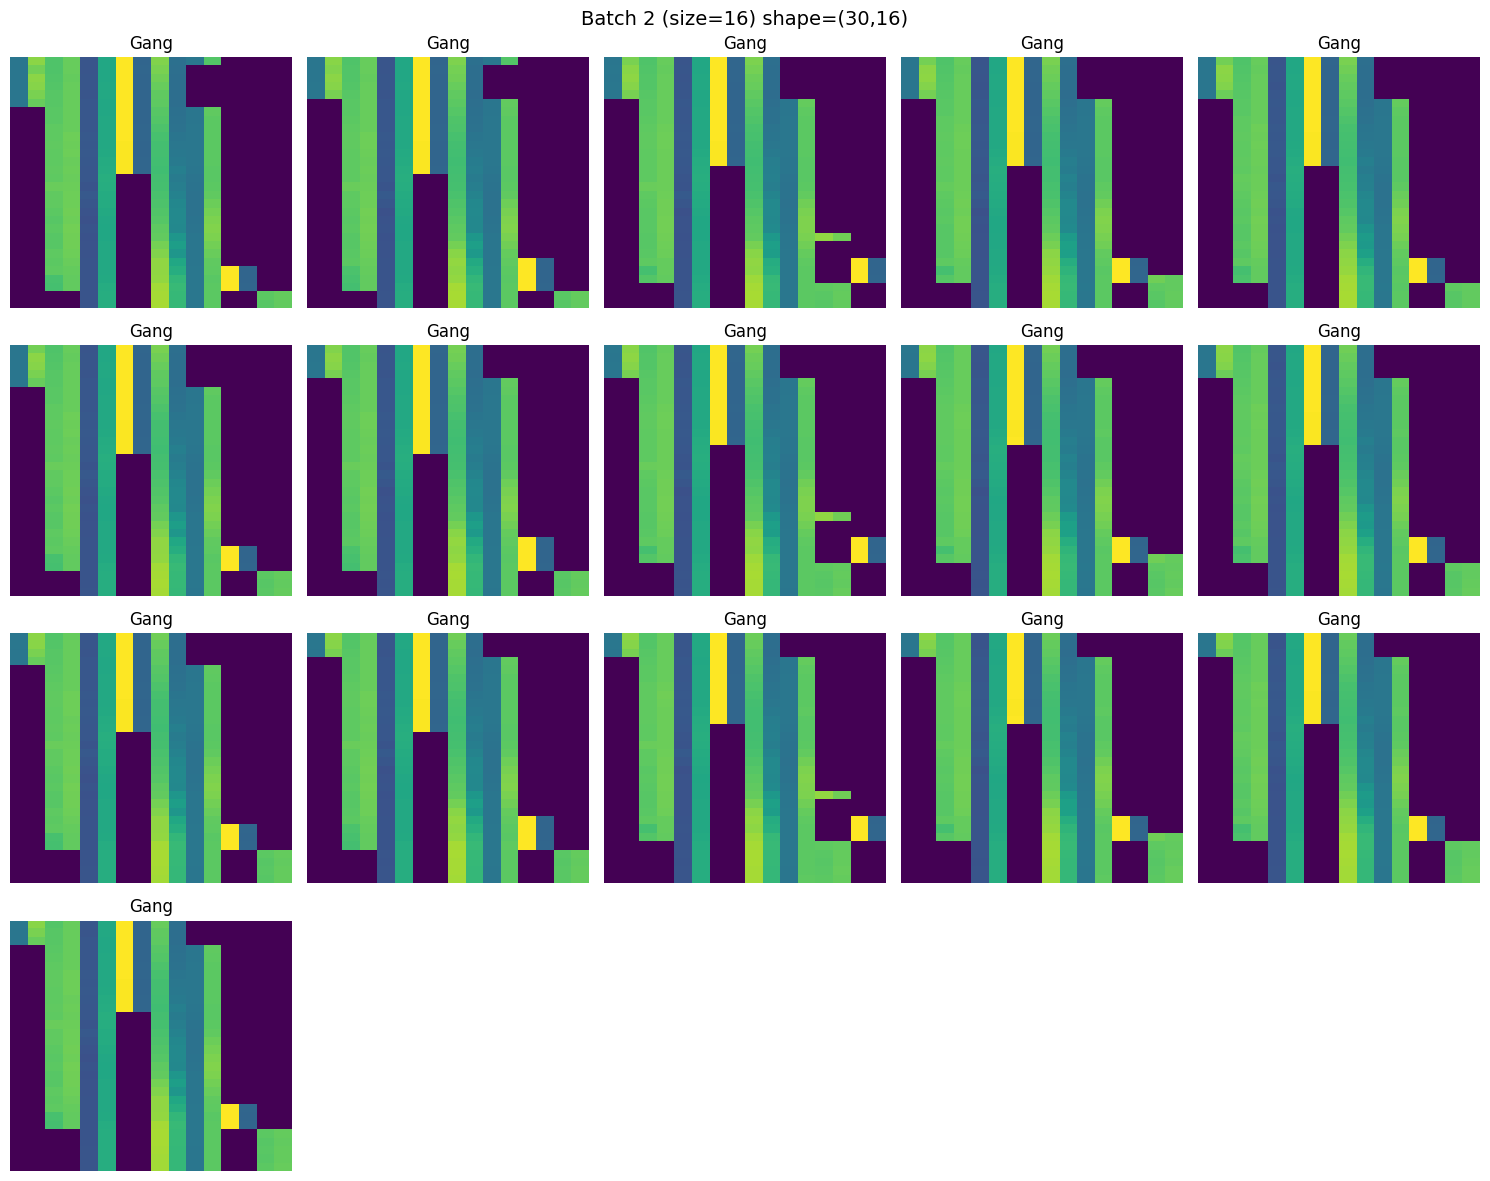

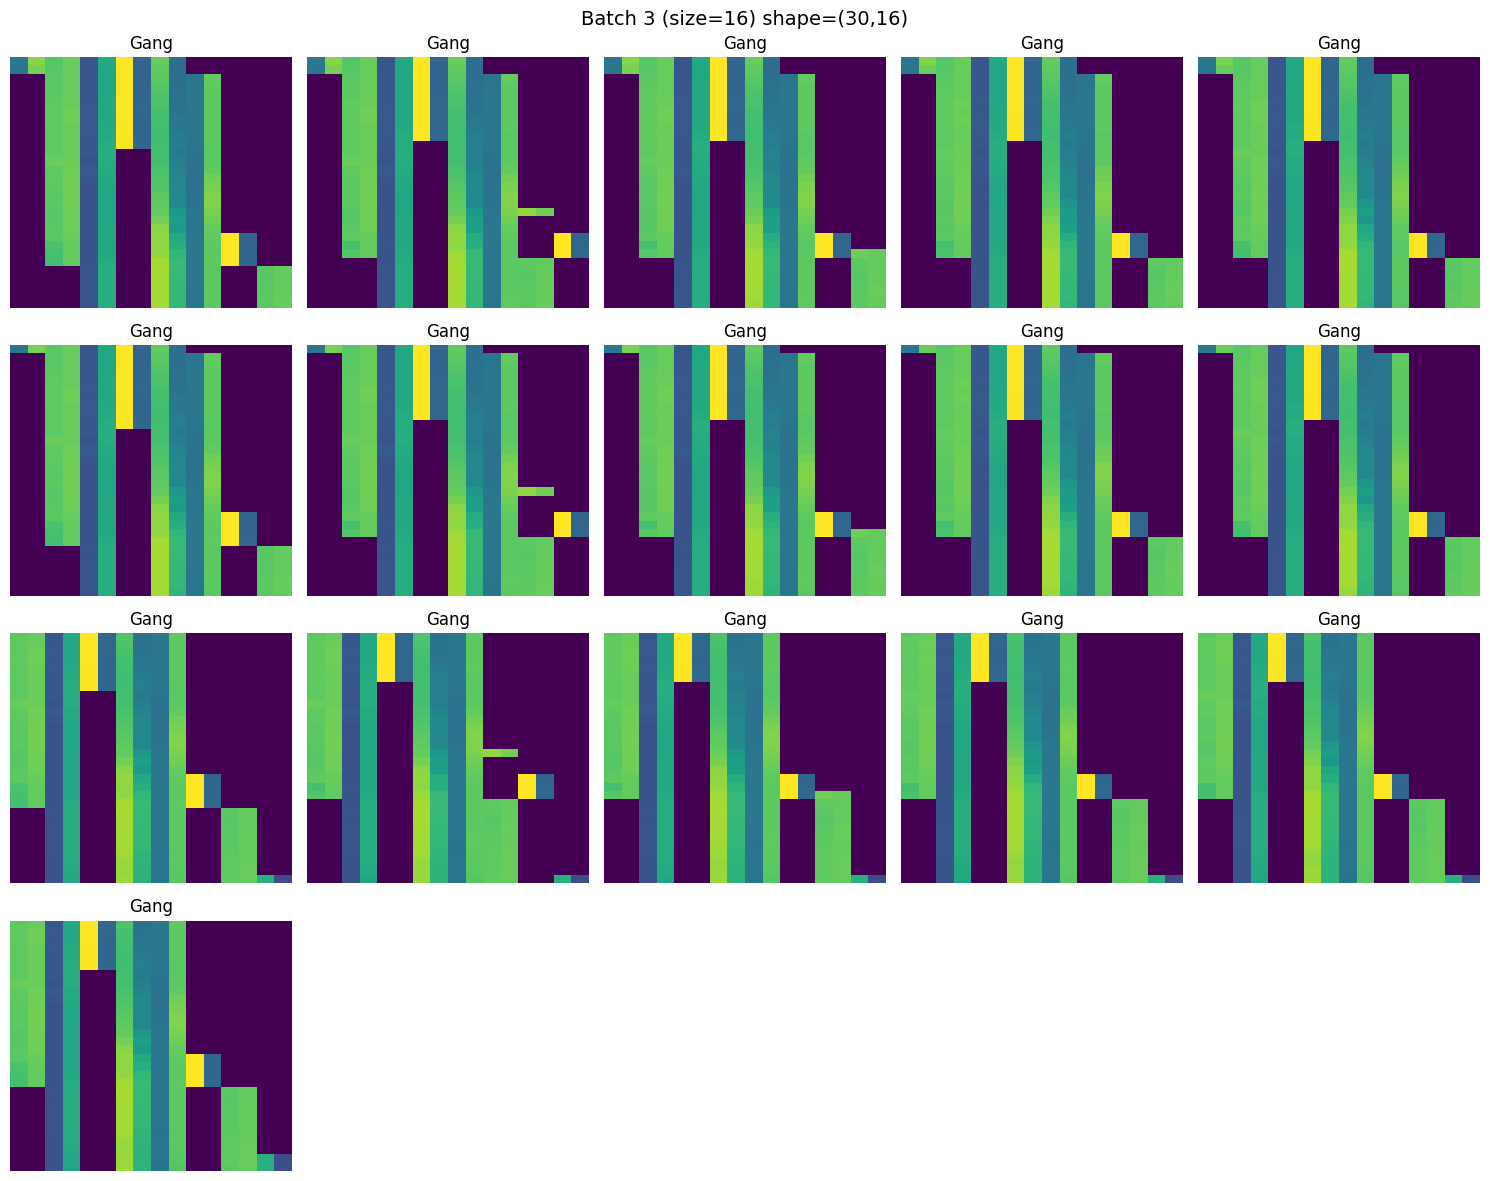

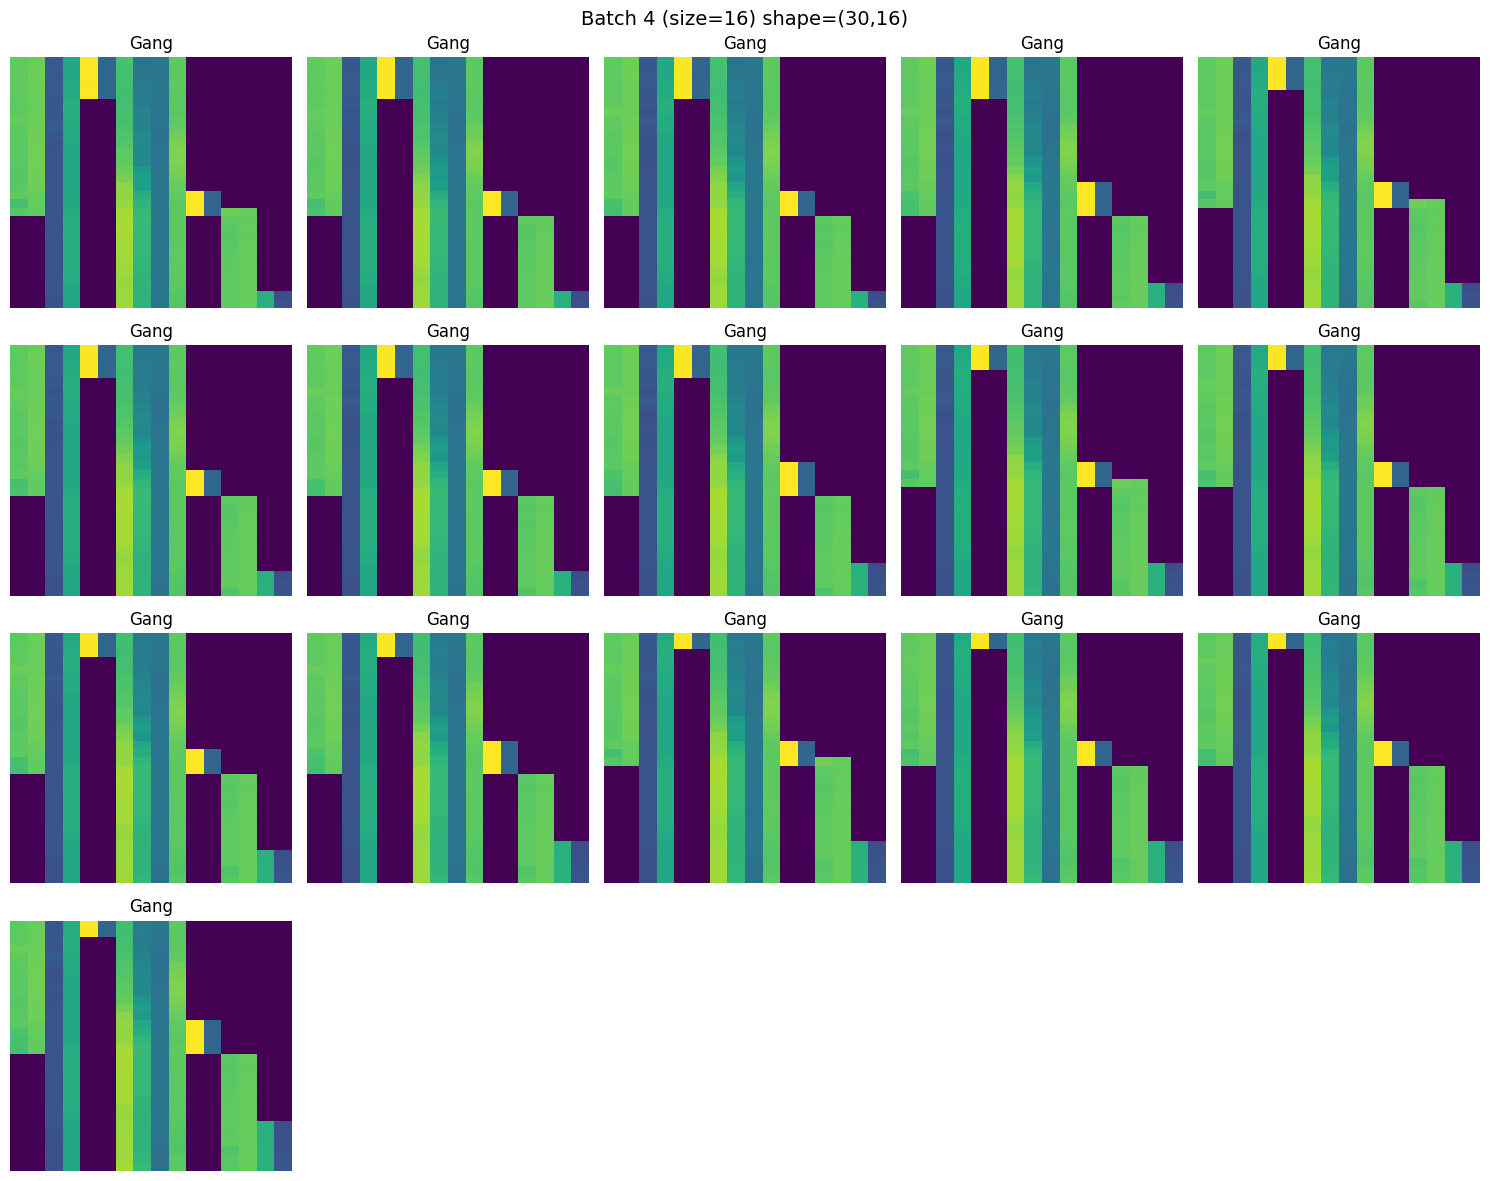

In [10]:
visualize_batches(loader, max_batches=5)